# Nonlinear ODE Problem Set Solutions

**References:** `Notes/Problem Set II.pdf` (Q2, Q4, Q5), `Notes/lec10.pdf`, `Notes/lec11.pdf`

Grouped by question type:
1. **Type 1:** 1D Nonlinear Flows & Fixed-Point Analysis (`Problem Set II.pdf` Q2 i, ii, iii)
2. **Type 2:** 2D Nonlinear Competition System (`Problem Set II.pdf` Q4)
3. **Type 3:** Bead on a Rotating Hoop & Overdamped Reduction (`Problem Set II.pdf` Q5)

---
## Type 1: 1D Nonlinear Flows (`Problem Set II.pdf` Q2)
### Q2 (i): $\dot{x} = rx + x^3 - x^5$
- **Fixed points:** $x^* = 0$ always, and $x^2 = \frac{1 \pm \sqrt{1 + 4r}}{2}$ (when positive).
- **Stability ($r > 0$):** $0$ is **unstable**; $\pm x^*_{\text{out}}$ are **stable** (at $r=0.4$: $x^* \approx \pm 1.1429$).
- **Stability ($r < 0$):** for $-0.25 < r < 0$, $0$ and outer pair are **stable**, inner pair is **unstable**; for $r < -0.25$, only $0$ exists (**stable**).

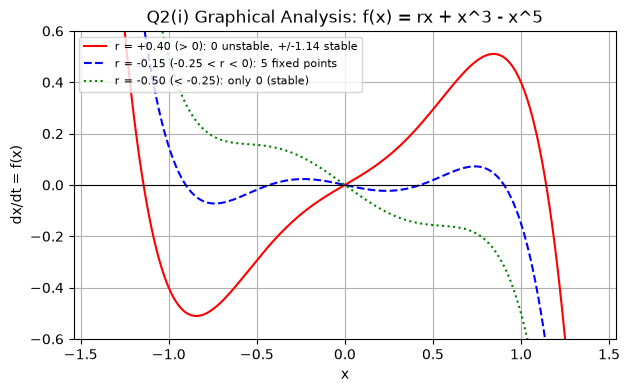

At r = 0.4: f'(0) = 0.4000 (unstable), f'(+/-1.1429) = -4.2125 (stable)
Final x(t) from +0.5: 1.1429
Final x(t) from -0.5: -1.1429


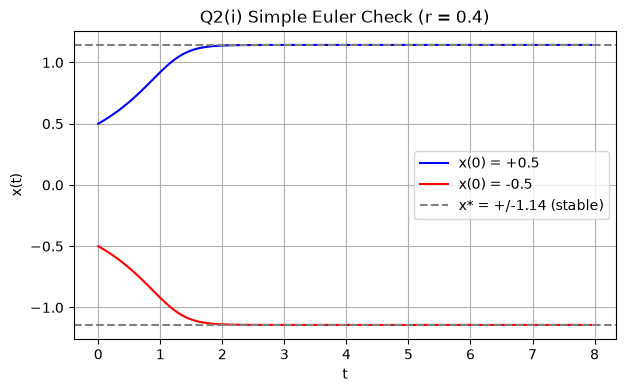

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Step 1: Graphical analysis of f(x) = r*x + x^3 - x^5 ---
# Crossing 0 downward (negative slope) = STABLE fixed point
# Crossing 0 upward   (positive slope) = UNSTABLE fixed point
x_grid = np.linspace(-1.4, 1.4, 400)

plt.figure(figsize=(7, 4))
plt.plot(x_grid,  0.40 * x_grid + x_grid**3 - x_grid**5, 'r-',  label='r = +0.40 (> 0): 0 unstable, +/-1.14 stable')
plt.plot(x_grid, -0.15 * x_grid + x_grid**3 - x_grid**5, 'b--', label='r = -0.15 (-0.25 < r < 0): 5 fixed points')
plt.plot(x_grid, -0.50 * x_grid + x_grid**3 - x_grid**5, 'g:',  label='r = -0.50 (< -0.25): only 0 (stable)')
plt.axhline(0, color='k', linewidth=0.8)  # horizontal axis where dx/dt = 0
plt.ylim(-0.6, 0.6)
plt.xlabel('x')
plt.ylabel('dx/dt = f(x)')
plt.title('Q2(i) Graphical Analysis: f(x) = rx + x^3 - x^5')
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

# --- Step 2: Simple Euler simulation for r = 0.4 ---
r = 0.4
dt = 0.05
t = np.arange(0, 8, dt)
n = len(t)

# Start two trajectories: one slightly positive (+0.5), one slightly negative (-0.5)
x_pos = np.zeros(n)
x_neg = np.zeros(n)
x_pos[0] = 0.5
x_neg[0] = -0.5

# Advance both in time using Simple Euler: x_next = x + dt * f(x)
for i in range(n - 1):
    x_pos[i + 1] = x_pos[i] + dt * (r * x_pos[i] + x_pos[i]**3 - x_pos[i]**5)
    x_neg[i + 1] = x_neg[i] + dt * (r * x_neg[i] + x_neg[i]**3 - x_neg[i]**5)

# Exact stable fixed point magnitude from x^2 = (1 + sqrt(1 + 4r)) / 2
x_star = np.sqrt((1 + np.sqrt(1 + 4 * r)) / 2)

# Check slopes f'(x) = r + 3*x^2 - 5*x^4 at x* = 0 and x* = +1.1429
slope_zero = r
slope_star = r + 3 * x_star**2 - 5 * x_star**4

print(f"At r = {r}: f'(0) = {slope_zero:.4f} (unstable), f'(+/-{x_star:.4f}) = {slope_star:.4f} (stable)")
print('Final x(t) from +0.5:', round(x_pos[-1], 4))
print('Final x(t) from -0.5:', round(x_neg[-1], 4))

# Plot trajectories to verify +0.5 settles at +1.14 and -0.5 settles at -1.14
plt.figure(figsize=(7, 4))
plt.plot(t, x_pos, 'b-', label='x(0) = +0.5')
plt.plot(t, x_neg, 'r-', label='x(0) = -0.5')
plt.axhline( x_star, color='gray', linestyle='--', label=f'x* = +/-{x_star:.2f} (stable)')
plt.axhline(-x_star, color='gray', linestyle='--')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('Q2(i) Simple Euler Check (r = 0.4)')
plt.legend()
plt.grid(True)
plt.show()

### Q2 (ii): Spruce Budworm $\dot{x} = \frac{2x}{5}\left(1 - \frac{x}{20}\right) - \frac{x^2}{1 + x^2}$
- **Fixed points ($x \ge 0$):** $x^* = 0$ and the 3 roots of $x^3 - 20x^2 + 51x - 20 = 0$: **$0.4805$**, **$2.4363$**, **$17.0831$**.
- **Stability ($f'(x^*)$):** $0$ (**unstable**), $0.4805$ (**stable**), $2.4363$ (**unstable** threshold), $17.0831$ (**stable**).

x* =  0.0000 | f'(x*) = +0.4000 -> Unstable (upward crossing)
x* =  0.4805 | f'(x*) = -0.2535 -> Stable (downward crossing)
x* =  2.4363 | f'(x*) = +0.2013 -> Unstable (upward crossing)
x* = 17.0831 | f'(x*) = -0.2837 -> Stable (downward crossing)


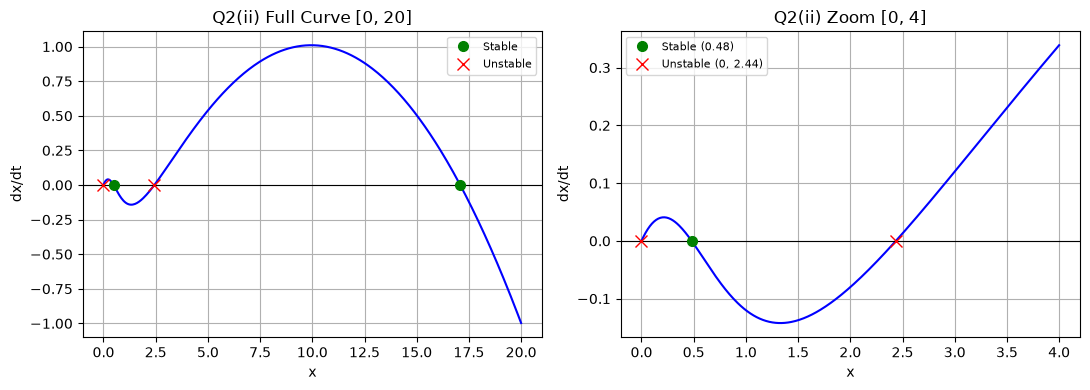

Euler check: x(0) =  0.1 -> final x(60) = 0.4805
Euler check: x(0) =  0.5 -> final x(60) = 0.4805
Euler check: x(0) =  2.0 -> final x(60) = 0.4805
Euler check: x(0) =  5.0 -> final x(60) = 17.0831
Euler check: x(0) = 18.0 -> final x(60) = 17.0831


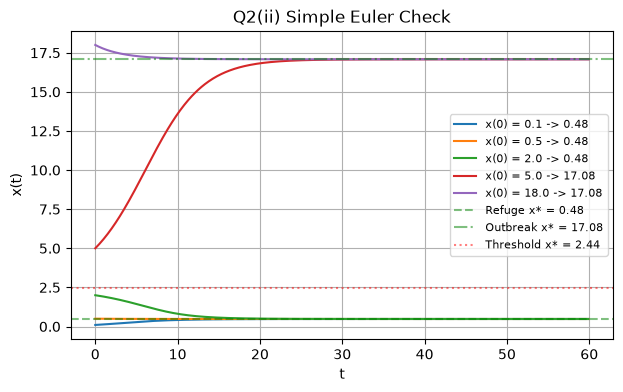

In [2]:
# --- Helper functions for f(x) and its derivative f'(x) ---
def budworm_f(x):
    return 0.4 * x * (1.0 - x / 20.0) - (x**2) / (1.0 + x**2)

def budworm_df(x):
    return 0.4 - 0.04 * x - (2.0 * x) / ((1.0 + x**2)**2)

# --- Step 1: Find all 4 fixed points using 1D Newton & check stability ---
# Note: for x < 0 both terms are negative, so fixed points exist only for x >= 0
fixed_pts = []
for guess in [0.0, 0.5, 2.5, 17.0]:
    xr = guess
    for step in range(20):
        xr = xr - budworm_f(xr) / budworm_df(xr)
    fixed_pts.append(xr)

    slope = budworm_df(xr)
    status = 'Stable (downward crossing)' if slope < 0 else 'Unstable (upward crossing)'
    print(f"x* = {xr:7.4f} | f'(x*) = {slope:+7.4f} -> {status}")

# --- Step 2: Graphical analysis (full range + zoom near 0..4) ---
plt.figure(figsize=(11, 4))

# Left plot: Full range [0, 20] shows all 4 roots (though 0, 0.48, 2.44 sit close together)
plt.subplot(1, 2, 1)
x_full = np.linspace(0, 20, 400)
plt.plot(x_full, budworm_f(x_full), 'b-')
plt.axhline(0, color='k', linewidth=0.8)
plt.plot([fixed_pts[1], fixed_pts[3]], [0, 0], 'go', markersize=7, label='Stable')
plt.plot([fixed_pts[0], fixed_pts[2]], [0, 0], 'rx', markersize=8, label='Unstable')
plt.xlabel('x'); plt.ylabel('dx/dt')
plt.title('Q2(ii) Full Curve [0, 20]')
plt.legend(fontsize=8); plt.grid(True)

# Right plot: Zoom [0, 4] clearly shows 0 (unstable), 0.48 (stable), and 2.44 (unstable)
plt.subplot(1, 2, 2)
x_zoom = np.linspace(0, 4, 400)
plt.plot(x_zoom, budworm_f(x_zoom), 'b-')
plt.axhline(0, color='k', linewidth=0.8)
plt.plot([fixed_pts[1]], [0], 'go', markersize=7, label='Stable (0.48)')
plt.plot([fixed_pts[0], fixed_pts[2]], [0, 0], 'rx', markersize=8, label='Unstable (0, 2.44)')
plt.xlabel('x'); plt.ylabel('dx/dt')
plt.title('Q2(ii) Zoom [0, 4]')
plt.legend(fontsize=8); plt.grid(True)

plt.tight_layout()
plt.show()

# --- Step 3: Simple Euler check from different initial populations ---
# Any start below the unstable tipping point 2.4363 drops/rises to 0.4805
# Any start above 2.4363 jumps to the outbreak level 17.0831
dt = 0.1
t = np.arange(0, 60, dt)

plt.figure(figsize=(7, 4))
for x0 in [0.1, 0.5, 2.0, 5.0, 18.0]:
    x = np.zeros(len(t))
    x[0] = x0
    for i in range(len(t) - 1):
        x[i + 1] = x[i] + dt * budworm_f(x[i])
    plt.plot(t, x, label=f'x(0) = {x0} -> {x[-1]:.2f}')
    print(f'Euler check: x(0) = {x0:4.1f} -> final x(60) = {x[-1]:.4f}')

plt.axhline(fixed_pts[1], color='g', linestyle='--', alpha=0.5, label='Refuge x* = 0.48')
plt.axhline(fixed_pts[3], color='g', linestyle='-.', alpha=0.5, label='Outbreak x* = 17.08')
plt.axhline(fixed_pts[2], color='r', linestyle=':',  alpha=0.5, label='Threshold x* = 2.44')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('Q2(ii) Simple Euler Check')
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

### Q2 (iii): $\dot{x} = rx - \ln(1 + x)$ ($x > -1$)
- **Always a fixed point at $x^* = 0$**, with slope $f'(0) = r - 1$ (transcritical bifurcation at $r = 1$).
- **$r > 1$:** $x^* = 0$ is **unstable**; second fixed point lies in **$(-1, 0)$** and is **stable** (at $r=1.3$: $x^* \approx -0.4230$).
- **$0 < r < 1$:** $x^* = 0$ is **stable**; second fixed point lies at **$x^* > 0$** and is **unstable** (at $r=0.7$: $x^* \approx +0.9650$). For $r \le 0$, only $x^* = 0$ (**stable**) exists.

r = 0.7 (< 1): x* = 0 (slope -0.30 -> stable), x* = +0.9650 (slope +0.1911 -> unstable)
r = 1.3 (> 1): x* = 0 (slope +0.30 -> unstable), x* = -0.4230 (slope -0.4330 -> stable)


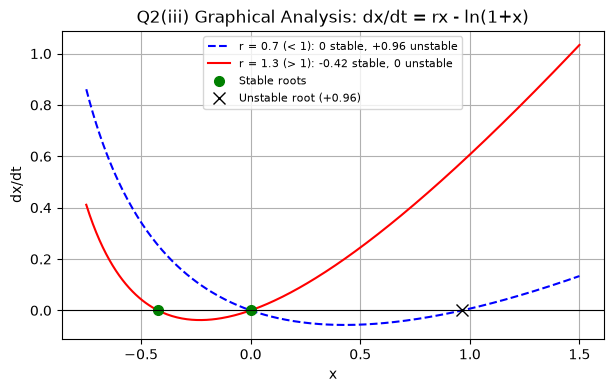

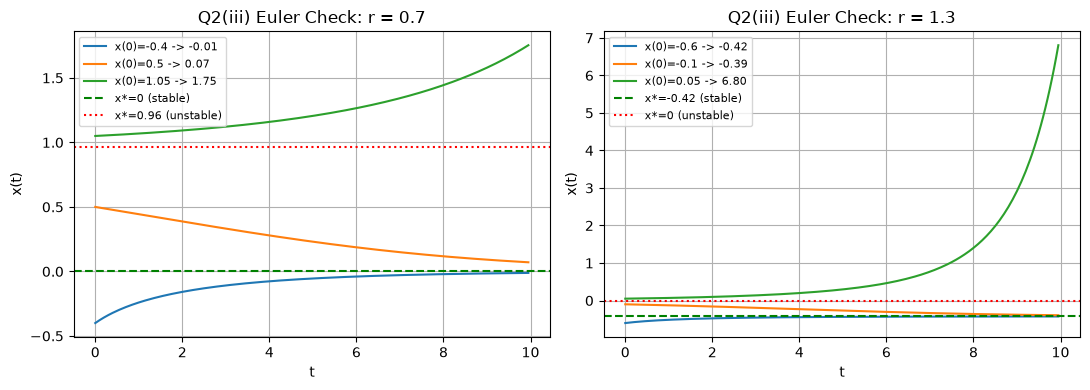

In [3]:
# --- Helper functions for f(x) = r*x - ln(1 + x) and f'(x) = r - 1/(1 + x) ---
def f3(x, r_val):
    return r_val * x - np.log(1.0 + x)

def df3(x, r_val):
    return r_val - 1.0 / (1.0 + x)

# --- Step 1: Find the non-zero fixed point using 1D Newton ---
def find_root_q2iii(r_val, guess):
    xr = guess
    for step in range(25):
        xr = xr - f3(xr, r_val) / df3(xr, r_val)
    return xr

x_star_07 = find_root_q2iii(0.7, 1.0)    # for r < 1, non-zero root is positive
x_star_13 = find_root_q2iii(1.3, -0.4)   # for r > 1, non-zero root is in (-1, 0)

print(f'r = 0.7 (< 1): x* = 0 (slope {df3(0, 0.7):+.2f} -> stable), x* = {x_star_07:+.4f} (slope {df3(x_star_07, 0.7):+.4f} -> unstable)')
print(f'r = 1.3 (> 1): x* = 0 (slope {df3(0, 1.3):+.2f} -> unstable), x* = {x_star_13:+.4f} (slope {df3(x_star_13, 1.3):+.4f} -> stable)')

# --- Step 2: Graphical analysis f(x) vs x ---
x_grid = np.linspace(-0.75, 1.5, 300)

plt.figure(figsize=(7, 4))
plt.plot(x_grid, f3(x_grid, 0.7), 'b--', label='r = 0.7 (< 1): 0 stable, +0.96 unstable')
plt.plot(x_grid, f3(x_grid, 1.3), 'r-',  label='r = 1.3 (> 1): -0.42 stable, 0 unstable')
plt.plot([0, x_star_13], [0, 0], 'go', markersize=7, label='Stable roots')
plt.plot([x_star_07], [0], 'kx', markersize=8, label='Unstable root (+0.96)')
plt.axhline(0, color='k', linewidth=0.8)
plt.xlabel('x')
plt.ylabel('dx/dt')
plt.title('Q2(iii) Graphical Analysis: dx/dt = rx - ln(1+x)')
plt.legend(fontsize=8)
plt.grid(True)
plt.show()

# --- Step 3: Simple Euler trajectory checks for r = 0.7 and r = 1.3 ---
dt = 0.05
t = np.arange(0, 10, dt)

plt.figure(figsize=(11, 4))

# Left plot (r = 0.7): starts below +0.96 settle at 0; start above +0.96 escapes right
plt.subplot(1, 2, 1)
for x0 in [-0.4, 0.5, 1.05]:
    x = np.zeros(len(t))
    x[0] = x0
    for i in range(len(t) - 1):
        x[i + 1] = x[i] + dt * f3(x[i], 0.7)
    plt.plot(t, x, label=f'x(0)={x0} -> {x[-1]:.2f}')
plt.axhline(0.0, color='g', linestyle='--', label='x*=0 (stable)')
plt.axhline(x_star_07, color='r', linestyle=':', label=f'x*={x_star_07:.2f} (unstable)')
plt.title('Q2(iii) Euler Check: r = 0.7')
plt.xlabel('t'); plt.ylabel('x(t)')
plt.legend(fontsize=8); plt.grid(True)

# Right plot (r = 1.3): starts in (-1, 0) settle at -0.42; start > 0 escapes right
plt.subplot(1, 2, 2)
for x0 in [-0.6, -0.1, 0.05]:
    x = np.zeros(len(t))
    x[0] = x0
    for i in range(len(t) - 1):
        x[i + 1] = x[i] + dt * f3(x[i], 1.3)
    plt.plot(t, x, label=f'x(0)={x0} -> {x[-1]:.2f}')
plt.axhline(x_star_13, color='g', linestyle='--', label=f'x*={x_star_13:.2f} (stable)')
plt.axhline(0.0, color='r', linestyle=':', label='x*=0 (unstable)')
plt.title('Q2(iii) Euler Check: r = 1.3')
plt.xlabel('t'); plt.ylabel('x(t)')
plt.legend(fontsize=8); plt.grid(True)

plt.tight_layout()
plt.show()

---
## Type 2: 2D Nonlinear Competition System (`Problem Set II.pdf` Q4)
System: $\dot{x} = x(3 - x - 2y)$, $\dot{y} = y(2 - y - x)$.
- **Fixed points ($\dot{x}=0, \dot{y}=0$):** $(0,0)$, $(3,0)$, $(0,2)$, and $(1,1)$.
- **Stability:** $(0,0)$ is an **unstable node** ($\lambda=3,2$); $(3,0)$ and $(0,2)$ are **stable nodes**; $(1,1)$ is a **saddle** ($\lambda=-1\pm\sqrt{2}$). Competitive exclusion means one species always wins.

Fixed point (0, 0): eigenvalues = [3.+0.j 2.+0.j]
Fixed point (3, 0): eigenvalues = [-3.+0.j -1.+0.j]
Fixed point (0, 2): eigenvalues = [-2.+0.j -1.+0.j]
Fixed point (1, 1): eigenvalues = [ 0.414+0.j -2.414+0.j]
Start (0.4, 0.2) -> Final (3.000, 0.000)
Start (2.0, 0.4) -> Final (3.000, 0.000)
Start (0.3, 1.8) -> Final (0.000, 2.000)
Start (2.5, 2.0) -> Final (0.020, 1.964)
Start (1.2, 0.9) -> Final (2.998, 0.001)
Start (0.8, 1.1) -> Final (0.000, 1.999)


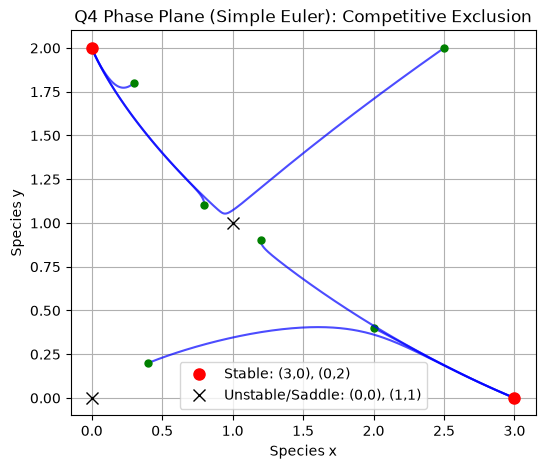

In [4]:
# --- Step 1: Check Jacobian eigenvalues at all 4 fixed points ---
# From dx/dt = x*(3 - x - 2y) = 0 and dy/dt = y*(2 - y - x) = 0:
#   (0, 0), (3, 0), (0, 2), and solving 3-x-2y=0 & 2-y-x=0 gives (1, 1)
fixed_points = [(0, 0), (3, 0), (0, 2), (1, 1)]

for fp in fixed_points:
    xs, ys = fp
    # Jacobian J = [[df/dx, df/dy], [dg/dx, dg/dy]]
    J = np.array([
        [3 - 2 * xs - 2 * ys, -2 * xs],
        [-ys,                  2 - 2 * ys - xs]
    ])
    vals = np.linalg.eigvals(J)
    print(f'Fixed point {fp}: eigenvalues = {np.round(vals, 3)}')

# Interpretation:
#   (0, 0): both > 0       -> Unstable node (repels populations)
#   (3, 0): both < 0       -> Stable node   (species x wins)
#   (0, 2): both < 0       -> Stable node   (species y wins)
#   (1, 1): +0.414, -2.414 -> Saddle        (coexistence is unstable)

# --- Step 2: Numerical phase plane check with Simple Euler ---
dt = 0.02
t = np.arange(0, 12, dt)
n = len(t)

plt.figure(figsize=(6, 5))
starts = [(0.4, 0.2), (2.0, 0.4), (0.3, 1.8), (2.5, 2.0), (1.2, 0.9), (0.8, 1.1)]

for x0, y0 in starts:
    x = np.zeros(n)
    y = np.zeros(n)
    x[0] = x0
    y[0] = y0

    for i in range(n - 1):
        dx = x[i] * (3 - x[i] - 2 * y[i])
        dy = y[i] * (2 - y[i] - x[i])
        x[i + 1] = x[i] + dt * dx
        y[i + 1] = y[i] + dt * dy

    plt.plot(x, y, 'b-', alpha=0.7)
    plt.plot(x[0], y[0], 'go', markersize=5)  # green dot = starting point
    print(f'Start ({x0:.1f}, {y0:.1f}) -> Final ({x[-1]:.3f}, {y[-1]:.3f})')

plt.plot([3, 0], [0, 2], 'ro', markersize=8, label='Stable: (3,0), (0,2)')
plt.plot([0, 1], [0, 1], 'kx', markersize=8, label='Unstable/Saddle: (0,0), (1,1)')
plt.xlabel('Species x')
plt.ylabel('Species y')
plt.title('Q4 Phase Plane (Simple Euler): Competitive Exclusion')
plt.legend()
plt.grid(True)
plt.show()

---
## Type 3: Bead on a Rotating Hoop (`Problem Set II.pdf` Q5)
Full equation: $mr\ddot{\varphi} = -br\dot{\varphi} - mg\sin\varphi + mr\omega^2\sin\varphi\cos\varphi$.
- **(i) Fixed points:** Slow spin $\to 2$ ($0, \pi$). Fast spin ($r\omega^2 > g$) $\to 4$: $0$, $\pi$, and $\pm\arccos(g/(r\omega^2)) \approx \pm 1.1680\text{ rad}$ (stable).
- **(ii) Timescales:** $\tau_{\text{damp}} = m/b$, $\tau_g = \sqrt{r/g}$, $\tau_\omega = 1/\omega$, and overdamped $\tau = br/(mg)$.
- **(iii) Overdamped reduction:** Rescaling $t = \tau\tilde{t}$ gives $\left(\frac{m^2 g}{b^2 r}\right)\varphi'' + \varphi' = -\sin\varphi + \frac{r\omega^2}{g}\sin\varphi\cos\varphi$. When $\frac{m^2 g}{b^2 r} \ll 1$, drop $\ddot{\varphi}$.
- **(iv) Parameters:** $m=1,\; b=20,\; \omega=5,\; r=1,\; g=9.8,\; \varphi(0)=0.5,\; \dot{\varphi}(0)=0$.

Timescales: tau_damp=0.0500s, tau_g=0.3194s, tau_w=0.2000s, tau=2.0408s
Overdamped check (m^2*g / (b^2*r)) = 0.0245 << 1 (valid!)
Analytical stable angle phi* = 1.1680 rad
Final phi_full(6s) = 1.1659, phi_over(6s) = 1.1654
Max difference for t >= tau: 2.0237e-03


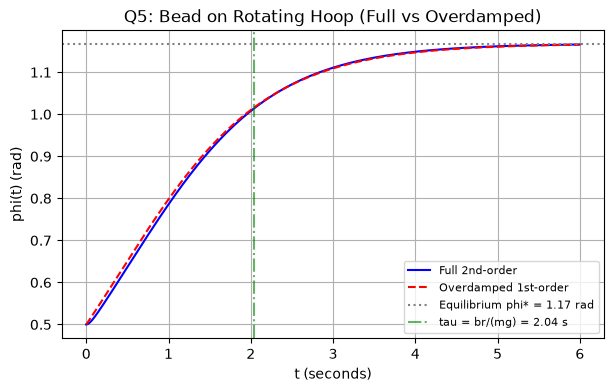

In [5]:
# --- Step 1: Physical parameters ---
m = 1.0       # mass
b = 20.0      # strong damping (friction)
omega = 5.0   # hoop rotation speed
r = 1.0       # hoop radius
g = 9.8       # gravity

# --- Step 2: Check timescales & overdamped condition (Parts ii & iii) ---
tau_damp = m / b                   # fast inertial damping decay (~0.05 s)
tau_g = np.sqrt(r / g)             # pendulum gravity scale (~0.32 s)
tau_omega = 1.0 / omega            # rotation scale (0.20 s)
tau = (b * r) / (m * g)            # slow overdamped relaxation scale (~2.04 s)
ratio = (m**2 * g) / (b**2 * r)    # must be << 1 to drop m*r*phi''

print(f'Timescales: tau_damp={tau_damp:.4f}s, tau_g={tau_g:.4f}s, tau_w={tau_omega:.4f}s, tau={tau:.4f}s')
print(f'Overdamped check (m^2*g / (b^2*r)) = {ratio:.4f} << 1 (valid!)')

# --- Step 3: Choose dt << tau_damp and integrate both equations (Part iv) ---
dt = 0.005    # much smaller than tau_damp = 0.05s so fast damping is resolved
t = np.arange(0, 6.0, dt)
n = len(t)

# Full 2nd-order state: phi and angular velocity v = d(phi)/dt
phi_full = np.zeros(n)
v_full = np.zeros(n)
phi_full[0] = 0.5
v_full[0] = 0.0

# Reduced 1st-order overdamped state (only phi)
phi_over = np.zeros(n)
phi_over[0] = 0.5

for i in range(n - 1):
    # Full 2nd-order: phi'' = (-b*r*v - m*g*sin + m*r*w^2*sin*cos) / (m*r)
    accel = (
        -b * r * v_full[i]
        - m * g * np.sin(phi_full[i])
        + m * r * (omega**2) * np.sin(phi_full[i]) * np.cos(phi_full[i])
    ) / (m * r)
    v_full[i + 1] = v_full[i] + dt * accel
    phi_full[i + 1] = phi_full[i] + dt * v_full[i + 1]   # Euler-Cromer keeps 2nd-order stable

    # Overdamped 1st-order (set phi'' = 0): phi' = (-m*g*sin + m*r*w^2*sin*cos) / (b*r)
    dphi = (
        -m * g * np.sin(phi_over[i])
        + m * r * (omega**2) * np.sin(phi_over[i]) * np.cos(phi_over[i])
    ) / (b * r)
    phi_over[i + 1] = phi_over[i] + dt * dphi

# --- Step 4: Compare with analytical equilibrium & check agreement after tau ---
phi_eq = np.arccos(g / (r * omega**2))  # exists because r*w^2 = 25 > g = 9.8
max_diff_after_tau = np.max(np.abs(phi_full[t >= tau] - phi_over[t >= tau]))

print(f'Analytical stable angle phi* = {phi_eq:.4f} rad')
print(f'Final phi_full(6s) = {phi_full[-1]:.4f}, phi_over(6s) = {phi_over[-1]:.4f}')
print(f'Max difference for t >= tau: {max_diff_after_tau:.4e}')

plt.figure(figsize=(7, 4))
plt.plot(t, phi_full, 'b-',  label='Full 2nd-order')
plt.plot(t, phi_over, 'r--', label='Overdamped 1st-order')
plt.axhline(phi_eq, color='gray', linestyle=':', label=f'Equilibrium phi* = {phi_eq:.2f} rad')
plt.axvline(tau, color='green', linestyle='-.', alpha=0.6, label=f'tau = br/(mg) = {tau:.2f} s')
plt.xlabel('t (seconds)')
plt.ylabel('phi(t) (rad)')
plt.title('Q5: Bead on Rotating Hoop (Full vs Overdamped)')
plt.legend(fontsize=8)
plt.grid(True)
plt.show()